# Лабораторная 5 — вариант 23

Сравнение PNG и JPEG качества 90 для визуала экологического лектория. Модель — SD-Turbo, seed 1023. Работа выполняется в Google Colab с GPU T4.

Библиотека, скрипт эксперимента и гипотеза загружаются отдельными файлами в разделе 3. Все вычисления основной пары выполняются в одном сеансе. Результаты сохраняются в архив

## 1. Проверка среды


In [1]:
from pathlib import Path
import subprocess, sys, importlib.metadata as metadata
ROOT = Path('/content/LR05')
ROOT.mkdir(parents=True, exist_ok=True)
gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv'], capture_output=True, text=True)
print(gpu.stdout or gpu.stderr)
if gpu.returncode:
    raise RuntimeError('GPU недоступен. В настройках среды выполнения требуется T4.')
versions = []
for name in ['torch', 'diffusers', 'transformers', 'Pillow', 'accelerate', 'safetensors']:
    try:
        versions.append(f'{name}=={metadata.version(name)}')
    except metadata.PackageNotFoundError:
        versions.append(f'{name}: not installed')
text = sys.version + '\n' + gpu.stdout + '\n'.join(versions)
(ROOT / 'environment_before.txt').write_text(text)
print(text)


name, memory.total [MiB]
Tesla T4, 15360 MiB

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
name, memory.total [MiB]
Tesla T4, 15360 MiB
torch==2.11.0+cu130
diffusers==0.40.0
transformers==5.18.0
Pillow==11.3.0
accelerate==1.15.0
safetensors==0.8.0


## 2. Зависимости

Устанавливаются библиотеки конвейера. Версии текущего сеанса записываются в манифест и requirements-freeze.txt. Установка выполняется до импорта PyTorch и Diffusers.

In [2]:
%pip install -q diffusers transformers accelerate safetensors Pillow


## 3. Гипотеза и допуск

# Гипотеза и критерии — вариант 23

Дата подготовки — 14.10.2026. Гипотеза записана до запуска модели.

Исследуется визуал для экологического лектория: полог леса сверху, зелёные слои и мягкий утренний свет. Используется исходный запрос брифа 4 из lab05_lib.py. Изображение служит стилизацией и не содержит сведений о состоянии реального леса.

Модель stabilityai/sd-turbo закреплена на ревизии b261bac6fd2cf515557d5d0707481eafa0485ec2. Параметры запуска: seed 1023, генератор на CPU, вычисления float16 на GPU, 512×512, один шаг, guidance_scale=0.0.

В основной паре меняется только формат сохранения. A — исходное изображение в PNG. B — это же изображение после сохранения в JPEG с quality=90 и декодирования обратно в RGB. Новая генерация для получения B не выполняется.

Ожидается, что PNG сохранит исходные пиксели точно, а JPEG уменьшит размер файла и изменит часть пикселей. В мелких переходах между зелёными слоями возможны потери деталей. Предполагается, что общая композиция сохранится, хотя PSNR может оказаться ниже 40 дБ. Фактическая глубина слоёв и видимость артефактов оцениваются по обеим картинкам после запуска.

Критерий задан до измерений. При одинаковых пикселях пара считается идентичной, PSNR принимается равным +∞. При разных пикселях и PSNR≥40 дБ пара практически совпадает; при PSNR<40 дБ изображения различаются по принятому допуску. Порог 40 дБ соответствует MSE=6.5025 на шкале 0–255. Он выбран в задании как учебный ориентир и не служит мерой художественного качества.

Фиксируются размеры файлов в байтах, SHA-256 исходных PNG и JPEG, SHA-256 PNG с декодированными JPEG-пикселями, равенство пикселей, максимальная абсолютная разность, MSE и PSNR. Для JPEG сохраняются фактические параметры субдискретизации и сведения о Pillow.

Контрольный повтор со свежим CPU-генератором и тем же seed предположительно даст одинаковое изображение в пределах одного сеанса. При двух последовательных вызовах с общим объектом Generator ожидается различие, поскольку первый вызов изменяет его состояние. Повтор с новым генератором должен восстановить исходный результат. Состояния генератора до и после вызовов сохраняются в виде контрольных сумм.

Дополнительная проверка кодирования — сохранение исходного изображения в PNG с уровнем сжатия 0. Ожидается совпадение пикселей с обычным PNG при возможном различии размера и хеша файла. Основной вывод о PNG/JPEG остаётся по quality=90 и порогу 40 дБ.


### Файлы эксперимента

Следующая ячейка последовательно открывает три окна загрузки. Для каждого окна над кнопкой выводится путь соответствующего файла в репозитории.

| Порядок | Файл |
|---|---|
| 1 | `src/lab05_lib.py` |
| 2 | `tools/run_lab05.py` |
| 3 | `reports/hypothesis.md` |

Файлы размещаются в подпапках `/content/LR05`. Их тексты сохраняются без изменений.


In [3]:
from pathlib import Path
import hashlib
from google.colab import files

ROOT = Path('/content/LR05')
paths = ['src/lab05_lib.py', 'tools/run_lab05.py', 'reports/hypothesis.md']

for relative in paths:
    destination = ROOT / relative
    print(f'Файл для загрузки: {relative}')
    uploaded = files.upload()
    if destination.name not in uploaded:
        raise ValueError(f'Ожидался файл {destination.name}. Загрузка остановлена.')
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(uploaded[destination.name])
    print('Сохранён:', destination)
    print('SHA-256:', hashlib.sha256(destination.read_bytes()).hexdigest())


Файл для загрузки: src/lab05_lib.py


Saving lab05_lib.py to lab05_lib.py
Сохранён: /content/LR05/src/lab05_lib.py
SHA-256: 4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a
Файл для загрузки: tools/run_lab05.py


Saving run_lab05.py to run_lab05.py
Сохранён: /content/LR05/tools/run_lab05.py
SHA-256: 7d03cc3c428554e34037a34851860d9914eeaf16eb6d8e31da83da053095fcab
Файл для загрузки: reports/hypothesis.md


Saving hypothesis.md to hypothesis.md
Сохранён: /content/LR05/reports/hypothesis.md
SHA-256: 56eef2769777e08aaca6e7f9ce7e5dac25cdd6070a729ee09597f640a42a12a4


## 4. Эксперимент

Выполняются загрузка и прогрев модели, генерация исходного PNG, преобразование в JPEG, сравнение пикселей и проверки генератора. Начальная загрузка весов занимает больше времени, чем последующие вызовы.

`RESULT: PASS` означает завершение скрипта. Классификация сравнения сохраняется отдельно. Значение `different` допустимо и не означает ошибку выполнения.


In [4]:
import sys
sys.path.insert(0, str(ROOT / 'tools'))
import run_lab05
result_dir = run_lab05.run_experiment()
print(result_dir)


Started: 2026-10-14T20:09:56.104309
Output: /content/LR05/artifacts/v23_20261014_200956_103633


[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "packages": {
    "torch": "2.11.0+cu130",
    "torchvision": "0.26.0+cu130",
    "diffusers": "0.40.0",
    "transformers": "5.18.0",
    "accelerate": "1.15.0",
    "safetensors": "0.8.0",
    "Pillow": "11.3.0",
    "numpy": "2.1.3",
    "huggingface-hub": "1.33.0"
  },
  "gpu": "Tesla T4",
  "gpu_memory_bytes": 15637086208,
  "cuda": "13.0",
  "cudnn": 92700,
  "deterministic_algorithms": false,
  "cudnn_benchmark": false,
  "matmul_allow_tf32": false
}


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

{
  "comparison": "PNG_vs_JPEG90",
  "sha_a_png": "c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e",
  "sha_b_png": "2f023f41bc300045f548cae0e45b97f2bd783030ad07a961e81fb1e2cf37f0f2",
  "pixel_equal": false,
  "max_diff": 44,
  "mse": 20.09080632527669,
  "psnr": 35.10082993776651,
  "verdict": "different"
}
{
  "comparison": "fresh_generator_repeat",
  "sha_a_png": "c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e",
  "sha_b_png": "c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e",
  "pixel_equal": true,
  "max_diff": 0,
  "mse": 0.0,
  "psnr": "Infinity",
  "verdict": "identical"
}
{
  "comparison": "shared_first_vs_baseline",
  "sha_a_png": "c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e",
  "sha_b_png": "c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e",
  "pixel_equal": true,
  "max_diff": 0,
  "mse": 0.0,
  "psnr": "Infinity",
  "verdict": "identical"
}
{
  "comparison": "shared_generator_two_calls

## 5. Изображения и таблица

В основной паре оценивается сохранение глубины зелёных слоёв, мягких переходов и деталей. Изображения показываются в одном масштабе.

**A — PNG**

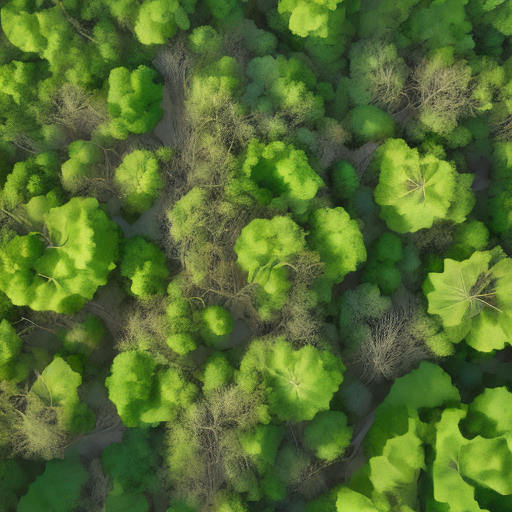

**B — JPEG, качество 90**

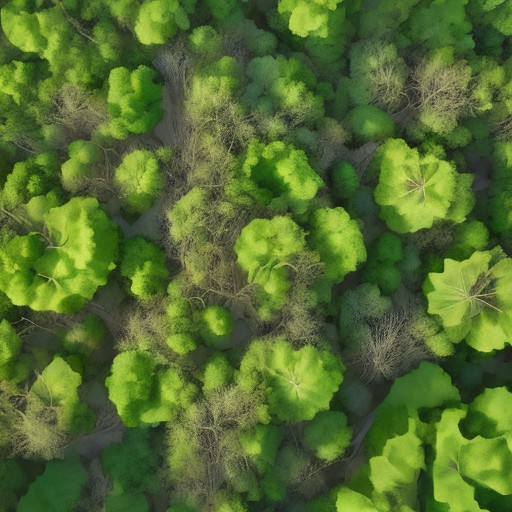

**Общий генератор, первый вызов**

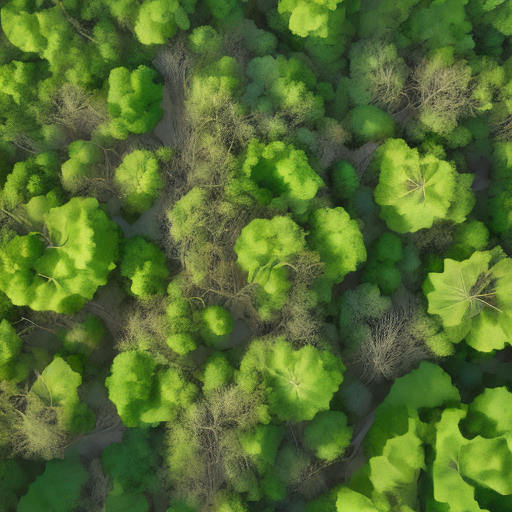

**Общий генератор, второй вызов**

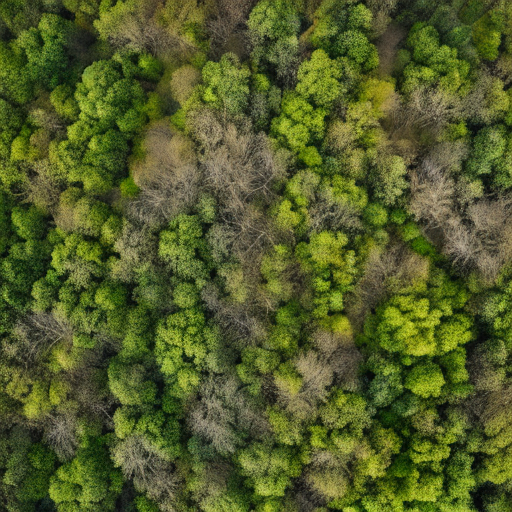

comparison,sha_a_png,sha_b_png,pixel_equal,max_diff,mse,psnr,verdict
PNG_vs_JPEG90,c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e,2f023f41bc300045f548cae0e45b97f2bd783030ad07a961e81fb1e2cf37f0f2,False,44,20.09080632527669,35.10082993776651,different
fresh_generator_repeat,c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e,c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e,True,0,0.0,Infinity,identical
shared_first_vs_baseline,c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e,c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e,True,0,0.0,Infinity,identical
shared_generator_two_calls,c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e,bd00b7de04cf4d689b5a4cfe079f24623526240d9f4149b60273b45b131f325d,False,200,2371.114702860514,14.381277973517793,different
fresh_generator_restores_baseline,c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334cb01570a4bc11e,c580cc8cfefc1ab2d83296a363576f16f7f4758e8b2323f334c

In [5]:
from IPython.display import display, Markdown
from PIL import Image
import json
for label, relative in [('A — PNG', 'A/result.png'), ('B — JPEG, качество 90', 'B/result.jpg'),
                        ('Общий генератор, первый вызов', 'controls/shared_generator_first.png'),
                        ('Общий генератор, второй вызов', 'controls/shared_generator_second.png')]:
    display(Markdown('**' + label + '**'))
    with Image.open(result_dir / relative) as im:
        display(im.copy())
print((result_dir / 'comparisons.csv').read_text())
print((result_dir / 'file_comparison.json').read_text())


## 6. Сохранение результатов

Архив содержит изображения, манифесты, метрики, журнал и исходные файлы. После завершения сеанса файлы виртуальной машины могут быть удалены. Выводы ячеек остаются в сохранённом IPYNB.


In [6]:
import shutil
from google.colab import files
shutil.copyfile(ROOT / 'environment_before.txt', result_dir / 'environment_before.txt')
archive = shutil.make_archive(str(result_dir), 'zip', root_dir=result_dir.parent, base_dir=result_dir.name)
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Источники

- [Карточка модели на закреплённой ревизии](https://huggingface.co/stabilityai/sd-turbo/blob/b261bac6fd2cf515557d5d0707481eafa0485ec2/README.md).
- [Лицензия модели](https://huggingface.co/stabilityai/sd-turbo/blob/b261bac6fd2cf515557d5d0707481eafa0485ec2/LICENSE.md).
- [Воспроизводимость в Diffusers](https://huggingface.co/docs/diffusers/using-diffusers/reusing_seeds).
